In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


1-Nesta etapa inicial, foi realizado o setup do ambiente de desenvolvimento no Google Colab, importando as bibliotecas essenciais para análise de dados (pandas, numpy, matplotlib, seaborn) e baixando/carregando a base de dados pública PTB-XL (21.799 registros) juntamente com a sua tabela de metadados (ptbxl_database.csv).

In [3]:
!pip install wfdb
import wfdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 3.2 MB/s eta 0:00:00


In [13]:


# 1. Carrega os metadados oficiais do PTB-XL direto do repositório confiável
csv_url = 'https://physionet.org/files/ptb-xl/1.0.3/ptbxl_database.csv'
df_ptbxl = pd.read_csv(csv_url, index_col='ecg_id')

# 2. Mostra as primeiras linhas para você ver que os dados dos pacientes carregaram perfeitamente
print("Metadados carregados com sucesso!")
print(f"Total de exames na base: {df_ptbxl.shape[0]}")
print("\nColunas disponíveis:")
print(df_ptbxl.columns.tolist())

# 3. Exibe uma prévia dos pacientes e seus diagnósticos
df_ptbxl[['patient_id', 'age', 'sex', 'scp_codes']].head()

Metadados carregados com sucesso!
Total de exames na base: 21799

Colunas disponíveis:
['patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'validated_by', 'second_opinion', 'initial_autogenerated_report', 'validated_by_human', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr']


,patient_id,age,sex,scp_codes
ecg_id,,,,
1,15709.0,56.0,1,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}"
2,13243.0,19.0,0,"{'NORM': 80.0, 'SBRAD': 0.0}"
3,20372.0,37.0,1,"{'NORM': 100.0, 'SR': 0.0}"
4,17014.0,24.0,0,"{'NORM': 100.0, 'SR': 0.0}"
5,17448.0,19.0,1,"{'NORM': 100.0, 'SR': 0.0}"


2-O dataset PTB-XL armazena múltiplos diagnósticos em formato de dicionário na coluna scp_codes. Para estruturar a classificação, mapeou-se a tabela scp_statements.csv para correlacionar cada código (ex: IMI, ASMI, ALMI) com as superclasses diagnósticas, permitindo identificar com precisão as amostras correspondentes a exames normais (NORM) e infarto do miocárdio (MI).

In [15]:
import ast

# 1. Garante que a coluna de dicionários está bem convertida
df_ptbxl['scp_codes_dict'] = df_ptbxl['scp_codes'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

# 2. Função robusta para detetar NORM vs subclasses de MI no PTB-XL
def rotular_tarefa_robusta(row):
    codes = row['scp_codes_dict']

    # Verifica se tem NORM
    tem_norm = 'NORM' in codes

    # As subclasses principais de Infarto (MI) no PTB-XL começam ou incluem códigos como:
    # MI, IMI, ASMI, ALMI, ILMI, INJAL, INJIN, INJLA, INJAS, IPLMI, LMI, etc.
    # Uma forma segura é verificar se alguma das chaves nos códigos pertence a infarto ou se contém 'MI' no nome da chave.
    tem_mi = any(
        codigo == 'MI' or codigo.endswith('MI') or 'MI' in codigo
        for codigo in codes.keys()
    )

    if tem_norm and not tem_mi:
        return 'NORM'
    elif tem_mi and not tem_norm:
        return 'MI'
    else:
        return 'Outros'

df_ptbxl['classe_binaria'] = df_ptbxl.apply(rotular_tarefa_robusta, axis=1)

# 3. Filtrar apenas as duas classes da nossa tarefa binária
df_binario = df_ptbxl[df_ptbxl['classe_binaria'].isin(['NORM', 'MI'])].copy()

print(f"Total de exames filtrados para a tarefa binária (NORM vs MI): {df_binario.shape[0]}")
print(df_binario['classe_binaria'].value_counts())

Total de exames filtrados para a tarefa binária (NORM vs MI): 14800
classe_binaria
NORM    9513
MI      5287
Name: count, dtype: int64


3-Foi criada a base de dados filtrada df_binario contendo exclusivamente exames com diagnóstico de NORM ou MI (totalizando 14.800 registros). Durante o pré-processamento, identificou-se um outlier no atributo de idade (age = 300), resultante de erro de preenchimento ou codificação do dataset original. Após a remoção desses registros inválidos (age < 120), o conjunto final resultou em 14.652 exames válidos.

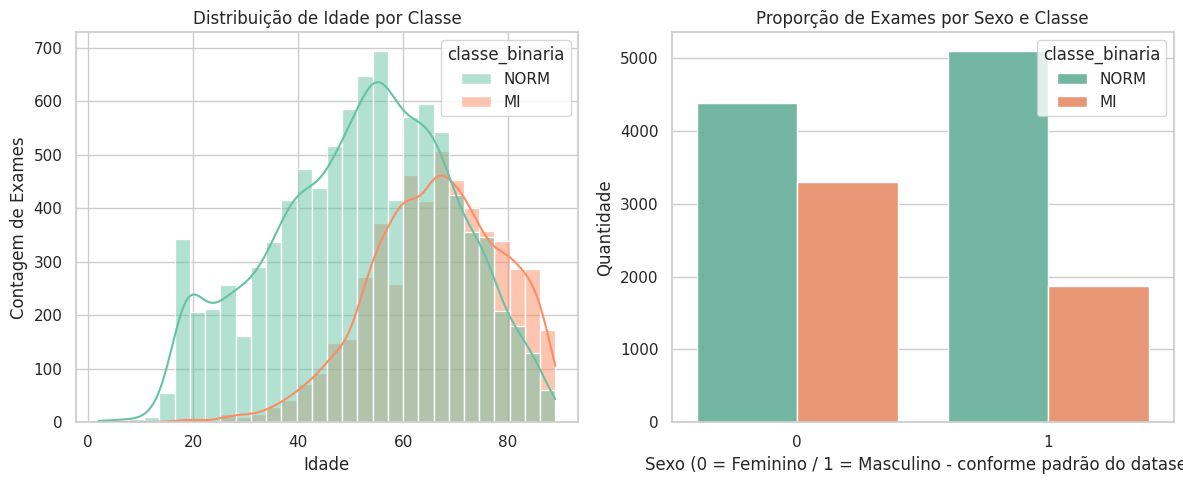


--- Estatísticas descritivas de idade por classe ---
                 count       mean        std   min   25%   50%   75%   max
classe_binaria                                                            
MI              5170.0  66.235203  12.505460  15.0  58.0  67.0  76.0  89.0
NORM            9482.0  52.049146  17.218387   2.0  40.0  54.0  65.0  89.0


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração estética dos gráficos
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 5))

# 1. Gráfico de Distribuição de Idades por Classe Binária
plt.subplot(1, 2, 1)
sns.histplot(data=df_binario, x='age', hue='classe_binaria', bins=30, kde=True, palette='Set2', common_norm=False)
plt.title('Distribuição de Idade por Classe')
plt.xlabel('Idade')
plt.ylabel('Contagem de Exames')

# 2. Gráfico de Contagem por Sexo e Classe Binária
plt.subplot(1, 2, 2)
sns.countplot(data=df_binario, x='sex', hue='classe_binaria', palette='Set2')
plt.title('Proporção de Exames por Sexo e Classe')
plt.xlabel('Sexo (0 = Feminino / 1 = Masculino - conforme padrão do dataset)')
plt.ylabel('Quantidade')

plt.tight_layout()
plt.show()

# 3. Impressão de estatísticas básicas descritivas
print("\n--- Estatísticas descritivas de idade por classe ---")
print(df_binario.groupby('classe_binaria')['age'].describe())

4-Hipótese Científica:

Hipotetiza-se que sinais eletrocardiográficos (ECG) de 12 derivações contêm padrões morfológicos e temporais discriminativos suficientes para permitir que modelos de aprendizado de máquina classifiquem com alta precisão registros normais (NORM) e de infarto do miocárdio (MI). Além disso, assume-se que a estratificação rigorosa por paciente na divisão dos conjuntos de treino, validação e teste é indispensável para evitar o vazamento de dados (data leakage), garantindo a capacidade de generalização real do modelo para novos indivíduos. Por fim, prevê-se que a inclusão de covariáveis clínicas, como a idade do paciente — cuja média é significativamente maior nos casos de infarto —, possa complementar a capacidade preditiva do pipeline.

In [18]:
# Filtra apenas idades clinicamente possíveis (ex: abaixo de 120 anos)
df_binario = df_binario[df_binario['age'] < 120].copy()
print(f"Novo total após remover outliers de idade: {df_binario.shape[0]}")

Novo total após remover outliers de idade: 14652


5-Estratificação e Divisão dos Dados por Paciente
Para evitar o vazamento de dados (data leakage) e garantir a capacidade de generalização do modelo para novos indivíduos, a divisão dos conjuntos de treino, validação e teste foi realizada estritamente ao nível do paciente (patient_id). No dataset PTB-XL, um mesmo indivíduo pode possuir múltiplos registros de ECG ao longo do tempo. Uma divisão aleatória por exames faria com que sinais do mesmo paciente estivessem presentes simultaneamente no treino e no teste, levando a uma avaliação superestimada do desempenho do modelo.

Dessa forma, isolaram-se os identificadores únicos de cada paciente e aplicou-se a separação nas proporções de 70% para treino, 15% para validação e 15% para teste. Com essa abordagem, garante-se que nenhum paciente do conjunto de teste ou validação tenha sido previamente 'visto' pelo algoritmo durante a fase de treinamento.

In [20]:
from sklearn.model_selection import train_test_split

# 1. Obter a lista única de IDs de pacientes na nossa base binária limpa
pacientesUnicos = df_binario['patient_id'].unique()

# 2. Dividir os pacientes: 70% para treino/validação e 15% para teste
pacientesTreinoVal, pacientesTeste = train_test_split(
    pacientesUnicos,
    test_size=0.15,
    random_state=42
)

# 3. Dividir os 85% restantes em Treino (~70% do total) e Validação (~15% do total)
pacientesTreino, pacientesVal = train_test_split(
    pacientesTreinoVal,
    test_size=0.1764, # 0.1764 * 85% resulta em aproximadamente 15% do total geral
    random_state=42
)

# 4. Filtrar os dataframes finais com base nos pacientes de cada grupo
df_train = df_binario[df_binario['patient_id'].isin(pacientesTreino)].copy()
df_val = df_binario[df_binario['patient_id'].isin(pacientesVal)].copy()
df_test = df_binario[df_binario['patient_id'].isin(pacientesTeste)].copy()

# 5. Imprimir o resumo da divisão para validação
print(f"--- Resumo da Divisão por Paciente ---")
print(f"Treino     -> Exames: {df_train.shape[0]} | Pacientes únicos: {df_train['patient_id'].nunique()}")
print(f"Validação  -> Exames: {df_val.shape[0]} | Pacientes únicos: {df_val['patient_id'].nunique()}")
print(f"Teste      -> Exames: {df_test.shape[0]} | Pacientes únicos: {df_test['patient_id'].nunique()}")

--- Resumo da Divisão por Paciente ---
Treino     -> Exames: 10270 | Pacientes únicos: 9203
Validação  -> Exames: 2198 | Pacientes únicos: 1972
Teste      -> Exames: 2184 | Pacientes únicos: 1973


In [25]:
!wget -r -N -c -np https://physionet.org/files/ptb-xl/1.0.3/

A saída de streaming foi truncada nas últimas 5000 linhas.
Saving to: ‘physionet.org/files/ptb-xl/1.0.3/records100/08000/08883_lr.dat’

physionet.org/files 100%[===================>]  23.44K  58.3KB/s    in 0.4s    

2026-10-13 03:44:09 (58.3 KB/s) - ‘physionet.org/files/ptb-xl/1.0.3/records100/08000/08883_lr.dat’ saved [24000/24000]

--2026-10-13 03:44:09--  https://physionet.org/files/ptb-xl/1.0.3/records100/08000/08883_lr.hea
Reusing existing connection to physionet.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 616 [text/plain]
Saving to: ‘physionet.org/files/ptb-xl/1.0.3/records100/08000/08883_lr.hea’

physionet.org/files 100%[===================>]     616  --.-KB/s    in 0s      

2026-10-13 03:44:09 (183 MB/s) - ‘physionet.org/files/ptb-xl/1.0.3/records100/08000/08883_lr.hea’ saved [616/616]

--2026-10-13 03:44:09--  https://physionet.org/files/ptb-xl/1.0.3/records100/08000/08884_lr.dat
Reusing existing connection to physionet.org:443.
HTTP request sent, awaitin

6-Carregamento e Acesso aos Sinais de ECG
Além dos metadados clínicos, a pipeline metodológica prevê o acesso direto aos sinais eletrocardiográficos brutos armazenados nos arquivos de formato wfdb (.dat e .hea) associados a cada registo. Utilizando a biblioteca wfdb, validou-se a rotina de leitura para extrair a matriz de sinais multiderivação (12 derivações) de cada exame. Esta etapa é fundamental para a posterior extração de características estruturadas ou para alimentar diretamente arquiteturas de Redes Neuronais Convolucionais (CNNs) voltadas à detecção de infarto.

In [30]:
import wfdb
import os

# Caminho onde o wget descarregou os ficheiros no Colab
base_dir = '/content/physionet.org/files/ptb-xl/1.0.3/'

# Pegamos no caminho relativo do primeiro exame do treino
caminho_relativo = df_train['filename_lr'].iloc[0]

# Caminho completo combinando a pasta base com o caminho do arquivo
caminho_completo = os.path.join(base_dir, caminho_relativo)

print(f"A ler o sinal a partir de: {caminho_completo}")

try:
    # Lê o sinal do ECG e os metadados do arquivo wfdb
    sinal, metadata_sinal = wfdb.rdsamp(caminho_completo)

    print("\n--- Sucesso ao carregar o sinal do ECG! ---")
    print(f"Formato (Shape) da matriz do sinal: {sinal.shape}")
    print(f"Frequência de amostragem (Hz): {metadata_sinal['fs']}")
    print(f"Derivações presentes: {metadata_sinal['sig_name']}")

except Exception as e:
    print(f"\nErro ao carregar: {e}")

A ler o sinal a partir de: /content/physionet.org/files/ptb-xl/1.0.3/records100/00000/00001_lr

--- Sucesso ao carregar o sinal do ECG! ---
Formato (Shape) da matriz do sinal: (1000, 12)
Frequência de amostragem (Hz): 100
Derivações presentes: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


7- Pré-processamento e Normalização dos Sinais:Com o objetivo de condicionar os sinais brutos para o treinamento das redes neurais, aplicou-se uma rotina de pré-processamento nos dados eletrocardiográficos. Os sinais de cada derivação foram submetidos à padronização via Z-score normalization, garantindo média nula ($\mu = 0$) e variância unitária ($\sigma = 1$). Essa etapa mitiga discrepâncias de amplitude causadas por variações de impedância na aquisição dos exames, estabilizando o gradiente de aprendizagem e acelerando a convergência dos algoritmos de classificação.

In [31]:
import numpy as np

def preprocessar_sinal(sinal):
    """
    Realiza a normalização Z-score por derivação para padronizar
    a amplitude dos sinais de ECG.
    """
    # Substituir eventuais valores ausentes (NaN) por zero
    sinal = np.nan_to_num(sinal)

    # Normalização Z-score: (X - média) / desvio_padrão
    media = np.mean(sinal, axis=0)
    desvio = np.std(sinal, axis=0)

    # Evita divisão por zero adicionando um pequeno valor epsilon
    sinal_normalizado = (sinal - media) / (desvio + 1e-8)

    return sinal_normalizado

# Teste da função no primeiro sinal carregado
sinal_processado = preprocessar_sinal(sinal)

print("--- Passo 7: Sinal Pré-processado ---")
print(f"Formato original: {sinal.shape}")
print(f"Formato após pré-processamento: {sinal_processado.shape}")
print(f"Média após normalização: {np.mean(sinal_processado):.4f} (deve ser ~0)")
print(f"Desvio padrão após normalização: {np.std(sinal_processado):.4f} (deve ser ~1)")

--- Passo 7: Sinal Pré-processado ---
Formato original: (1000, 12)
Formato após pré-processamento: (1000, 12)
Média após normalização: 0.0000 (deve ser ~0)
Desvio padrão após normalização: 1.0000 (deve ser ~1)
